# Optimise Models 
Sampling


## 1. Import Libraries

In [1]:
import os
import pandas as pd

from sklearn.model_selection import StratifiedKFold

from config_optimisation import (
    RANDOM_STATE,
    N_SPLITS,
    AT_RISK_RULES,
    COMBINED_AT_RISK_RULES,
    GROUP_COUNT_COLS,
    CONFUSION_COUNT_COLS,
    UNDERSAMPLING_METHOD,
    UNDERSAMPLING_COMBINED_METHOD,
    NON_RISK_PER_RISK_VALUES,
)
from optimisation_helpers import (
    load_model_data,
    make_output_dir,
    get_at_risk_groups,
    count_classes,
    get_skip_reason,
    fit_and_predict,
    evaluate_in_subgroups,
    save_with_sdc,
    plot_confusion_matrices,
    get_at_risk_mask
) 

## 2. Settings

In [2]:
OPTIMISATION_METHOD = UNDERSAMPLING_METHOD
OPTIMISATION_DIR = make_output_dir(OPTIMISATION_METHOD)


## 3. Load Data

In [3]:
data = load_model_data()

X_train = data["X_train"]
y_train = data["y_train"]

X_test = data["X_test"]
y_test = data["y_test"]

train_subgroups = data["train_subgroups"]
test_subgroups = data["test_subgroups"]

print("Training data:", X_train.shape)
print("Test data:", X_test.shape)
print("At-risk groups:", AT_RISK_RULES)

Training data: (4000, 87)
Test data: (1000, 87)
At-risk groups: {'age_band': ['75-79', '80-84', '85-89', '90-94', '95-99', '100+'], 'sex': ['female'], 'ethnicity_cat': ['Black', 'Asian'], 'imd_quintile': ['1 (most deprived)', '2'], 'rural_urban': [5, 6, 7, 8], 'mltc_count': {'min': 2}, 'migrant': [1], 'learndis': [1], 'non_english_speaking': [1], 'smi': [1], 'substance_abuse': [1], 'homeless': [1], 'housebound': [1]}


## 4. Cross Validation

In [4]:
cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

## 5. Sample, train and evaluate for each at-risk subgroup

In [18]:
performance_rows = []
subgroup_rows = []
skipped_rows = []

for group in get_at_risk_groups(
    test_subgroups,
    train_subgroups=train_subgroups,
):

    if not group["test_mask"].any():
        continue

    risk_mask = group["train_mask"]

    risk_data = X_train.loc[risk_mask]
    non_risk_data = X_train.loc[~risk_mask]

    for ratio in NON_RISK_PER_RISK_VALUES:

        sampling_info = {
            "sampling_variable": group["subgroup_variable"],
            "sampling_level": group["subgroup_level"],
            "level_number": group["level_number"],
            "non_risk_per_risk": ratio,
        }

        n_non_risk = min(
            len(non_risk_data),
            int(len(risk_data) * ratio),
        )

        if n_non_risk == len(non_risk_data):
            skipped_rows.append({
                **sampling_info,
                "reason": "No patients would be removed",
            })
            continue

        sampled_non_risk = non_risk_data.sample(
            n=n_non_risk,
            random_state=RANDOM_STATE,
        )

        selected_rows = risk_data.index.append(sampled_non_risk.index)

        X_train_sampled = X_train.loc[selected_rows].copy()
        y_train_sampled = y_train.loc[selected_rows].copy()

        counts = count_classes(
            y_train=y_train_sampled,
            y_test=y_test,
        )

        reason = get_skip_reason(counts)

        if reason is not None:
            skipped_rows.append({
                **sampling_info,
                "reason": reason,
            })
            continue

        print(
            f"Sampling for: "
            f"{group['subgroup_variable']} = {group['subgroup_level']}, "
            f"ratio = {ratio}"
        )
        print("Training patients before sampling:", len(X_train))
        print("Training patients after sampling:", len(X_train_sampled))
        print("Selected subgroup patients retained:", len(risk_data))
        print("Other patients retained:", len(sampled_non_risk))

        group_dir = os.path.join(
            OPTIMISATION_DIR,
            f"ratio_{ratio}",
            group["subgroup_variable"],
            f"level_{group['level_number']}",
        )

        performance, predictions = fit_and_predict(
            X_train=X_train_sampled,
            y_train=y_train_sampled,
            X_test=X_test,
            y_test=y_test,
            test_ids=data["test_ids"],
            out_dir=group_dir,
            cv=cv,
            # threshold from the original (not sampled) training set
            X_threshold=X_train,
            y_threshold=y_train,
        )

        subgroup_performance = evaluate_in_subgroups(
            prediction_df=predictions,
            test_subgroups=test_subgroups,
        )

        for column, value in counts.items():
            performance[column] = value

        for column, value in sampling_info.items():
            performance[column] = value
            subgroup_performance[column] = value

        save_with_sdc(
            performance,
            os.path.join(group_dir, "test_performance.csv"),
            count_cols=GROUP_COUNT_COLS + CONFUSION_COUNT_COLS,
        )

        save_with_sdc(
            subgroup_performance,
            os.path.join(group_dir, "subgroup_test_performance.csv"),
            count_cols=[
                "n_test",
                "test_events",
                "test_nonevents",
                *CONFUSION_COUNT_COLS,
            ],
        )

        predictions.to_csv(
            os.path.join(group_dir, "test_predictions.csv.gz"),
            index=False,
            compression="gzip",
        )

        performance_rows.append(performance)
        subgroup_rows.append(subgroup_performance)


Sampling for: age_band = 75-79, 80-84, 85-89, 90-94, 95-99, 100+, ratio = 0.5
Training patients before sampling: 4000
Training patients after sampling: 3172
Selected subgroup patients retained: 2115
Other patients retained: 1057
Fitting 5 folds for each of 6 candidates, totalling 30 fits
lr: best CV roc_auc = 0.5767
lr: best params = {'model__C': 0.1, 'model__l1_ratio': 0.5, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
rf: best CV roc_auc = 0.5827
rf: best params = {'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced'}
Fitting 5 folds for each of 20 candidates, totalling 100 fits
hgb: best CV roc_auc = 0.5765
hgb: best params = {'max_iter': 200, 'max_depth': 2, 'learning_rate': 0.01}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
xgb: best CV roc_auc = 0.5805
xgb: best params = {'subsample': 0.7

/Users/cu20932/Documents/Work/reducehf/fresh_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


lr: best CV roc_auc = 0.5753
lr: best params = {'model__C': 1, 'model__penalty': 'l2', 'model__solver': 'saga'}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
rf: best CV roc_auc = 0.5937
rf: best params = {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 10, 'criterion': 'log_loss', 'class_weight': 'balanced'}
Fitting 5 folds for each of 20 candidates, totalling 100 fits
hgb: best CV roc_auc = 0.5667
hgb: best params = {'max_iter': 400, 'max_depth': 3, 'learning_rate': 0.001}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
xgb: best CV roc_auc = 0.5645
xgb: best params = {'subsample': 0.7, 'scale_pos_weight': 0.1927710843373494, 'n_estimators': 400, 'max_depth': 3, 'learning_rate': 0.01, 'gamma': 0, 'colsample_bytree': 0.2}
Sampling for: rural_urban = 5, 6, 7, 8, ratio = 0.5
Training patients before sampling: 4000
Training patients after sampling: 742
Selected subgroup patients retained: 495
Other pat

/Users/cu20932/Documents/Work/reducehf/fresh_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/Users/cu20932/Documents/Work/reducehf/fresh_env/lib/python3.9/site-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


lr: best CV roc_auc = 0.5760
lr: best params = {'model__C': 0.1, 'model__l1_ratio': 0.5, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
rf: best CV roc_auc = 0.6176
rf: best params = {'n_estimators': 150, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 40, 'criterion': 'entropy', 'class_weight': 'balanced'}
Fitting 5 folds for each of 20 candidates, totalling 100 fits
hgb: best CV roc_auc = 0.5868
hgb: best params = {'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.1}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
xgb: best CV roc_auc = 0.5963
xgb: best params = {'subsample': 0.5, 'scale_pos_weight': 0.24709103353867215, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.001, 'gamma': 0.2, 'colsample_bytree': 0.2}
Sampling for: learndis = 1, ratio = 1
Training patients before sampling: 4000
Training patients after sampling: 508
Selected subgroup patients re

## 6. Combine and Save 

In [6]:

skipped_df = pd.DataFrame(
    skipped_rows,
    columns=[
        "sampling_variable",
        "sampling_level",
        "level_number",
        "non_risk_per_risk",
        "reason",
    ],
)

skipped_df.to_csv(
    os.path.join(OPTIMISATION_DIR, "skipped_subgroups.csv"),
    index=False,
)

performance_df = pd.concat(
    performance_rows,
    ignore_index=True,
)

subgroup_performance_df = pd.concat(
    subgroup_rows,
    ignore_index=True,
)

save_with_sdc(
    performance_df,
    os.path.join(OPTIMISATION_DIR, "test_performance.csv"),
    count_cols=GROUP_COUNT_COLS + CONFUSION_COUNT_COLS,
)

save_with_sdc(
    subgroup_performance_df,
    os.path.join(
        OPTIMISATION_DIR,
        "subgroup_test_performance.csv",
    ),
    count_cols=[
        "n_test",
        "test_events",
        "test_nonevents",
        *CONFUSION_COUNT_COLS,
    ],
)

print("Sampling experiments fitted:", len(performance_rows))
print("Sampling experiments skipped:", len(skipped_df))
print("Saved results to:", OPTIMISATION_DIR)

Sampling experiments fitted: 21
Sampling experiments skipped: 1
Saved results to: /Users/cu20932/Documents/Work/reducehf/output/models/optimisation/undersampling


## 7. Check 

In [7]:
display(
    performance_df[
        [
            "sampling_variable",
            "sampling_level",
            "model",
            "n_train",
            "auc",
            "auc_pr",
            "brier",
            "threshold",
        ]
    ].head(20)
)

display(skipped_df)

,sampling_variable,sampling_level,model,n_train,auc,auc_pr,brier,threshold
0,age_band,"75-79, 80-84, 85-89, 90-94, 95-99, 100+",lr,3172,0.554526,0.831519,0.247741,0.410744
1,age_band,"75-79, 80-84, 85-89, 90-94, 95-99, 100+",rf,3172,0.572820,0.843191,0.216710,0.477221
2,age_band,"75-79, 80-84, 85-89, 90-94, 95-99, 100+",hgb,3172,0.580257,0.845550,0.156126,0.769488
3,age_band,"75-79, 80-84, 85-89, 90-94, 95-99, 100+",xgb,3172,0.589066,0.844716,0.236076,0.457930
4,sex,female,lr,3544,0.562219,0.832825,0.250202,0.417769
5,sex,female,rf,3544,0.570766,0.834622,0.219209,0.477628
6,sex,female,hgb,3544,0.574053,0.836136,0.157571,0.749755
7,sex,female,xgb,3544,0.582758,0.836423,0.238246,0.464236
8,sex,female,lr,2658,0.542724,0.820479,0.250824,0.407170
9,sex,female,rf,2658,0.549134,0.824351,0.191134,0.538937


,sampling_variable,sampling_level,level_number,non_risk_per_risk,reason
0,age_band,"75-79, 80-84, 85-89, 90-94, 95-99, 100+",0,1,No patients would be removed


## 8. Plot Confusion Matrices

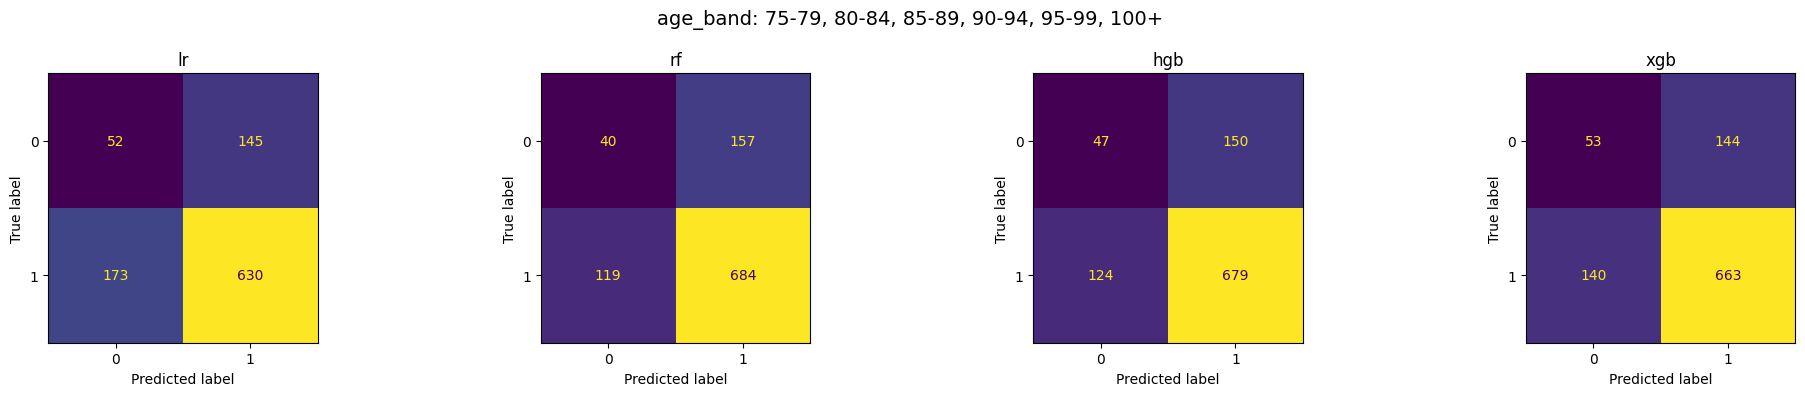

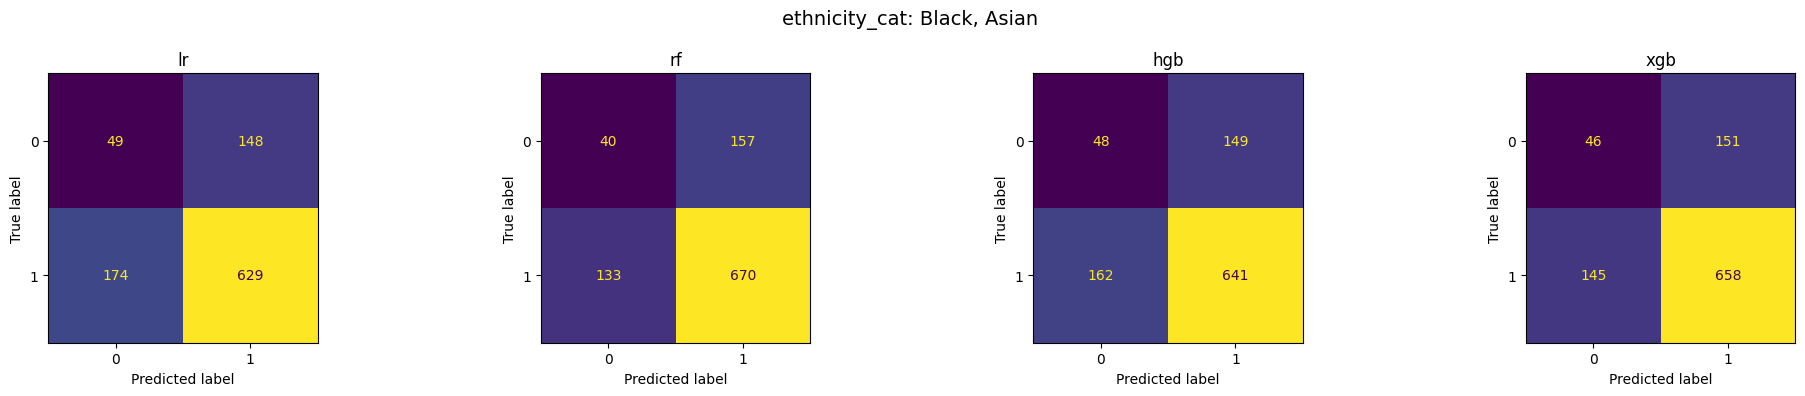

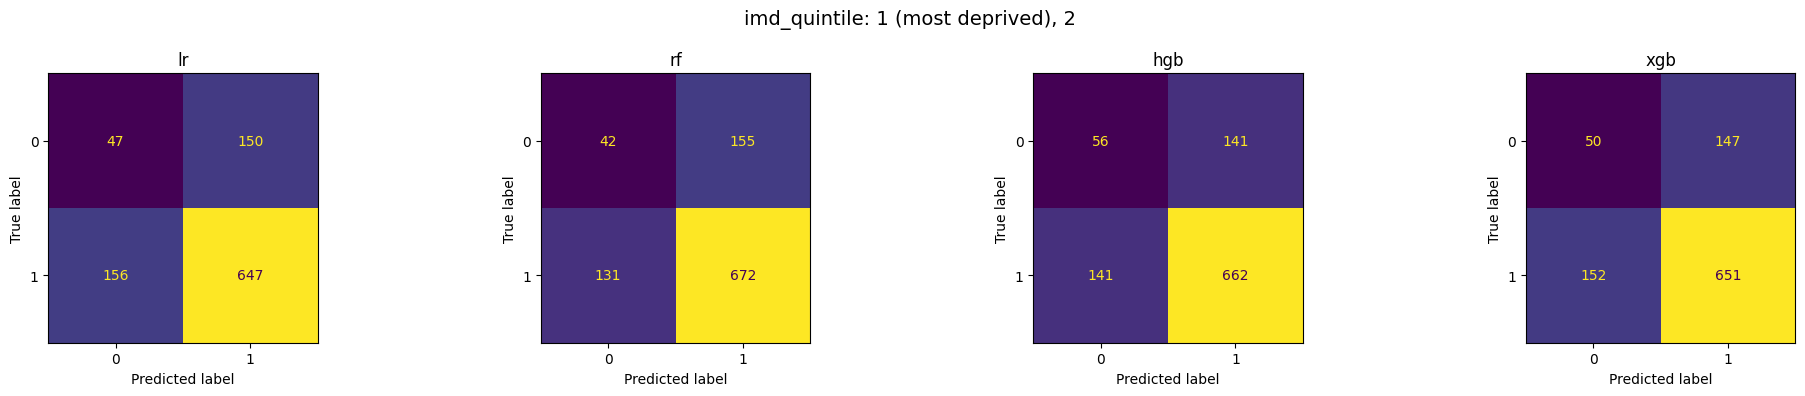

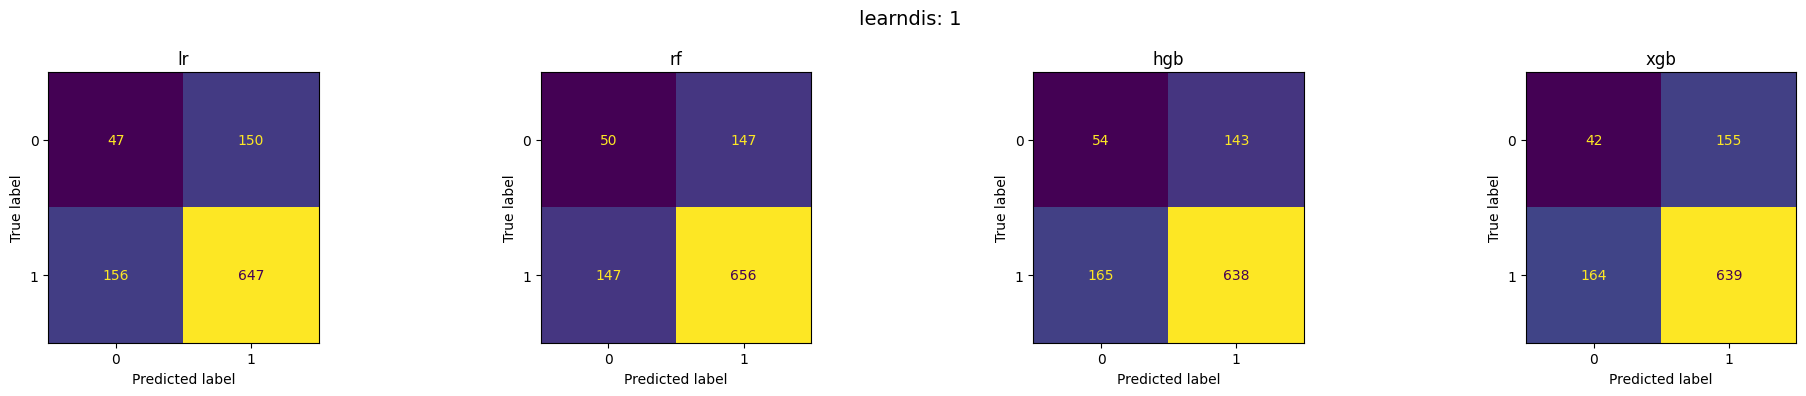

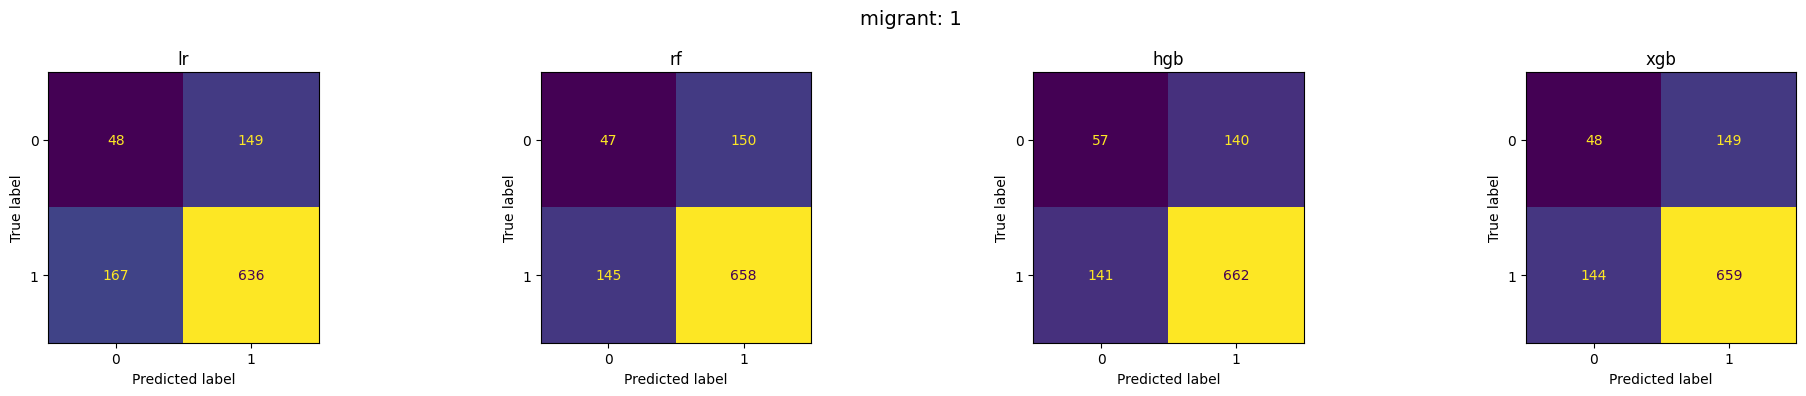

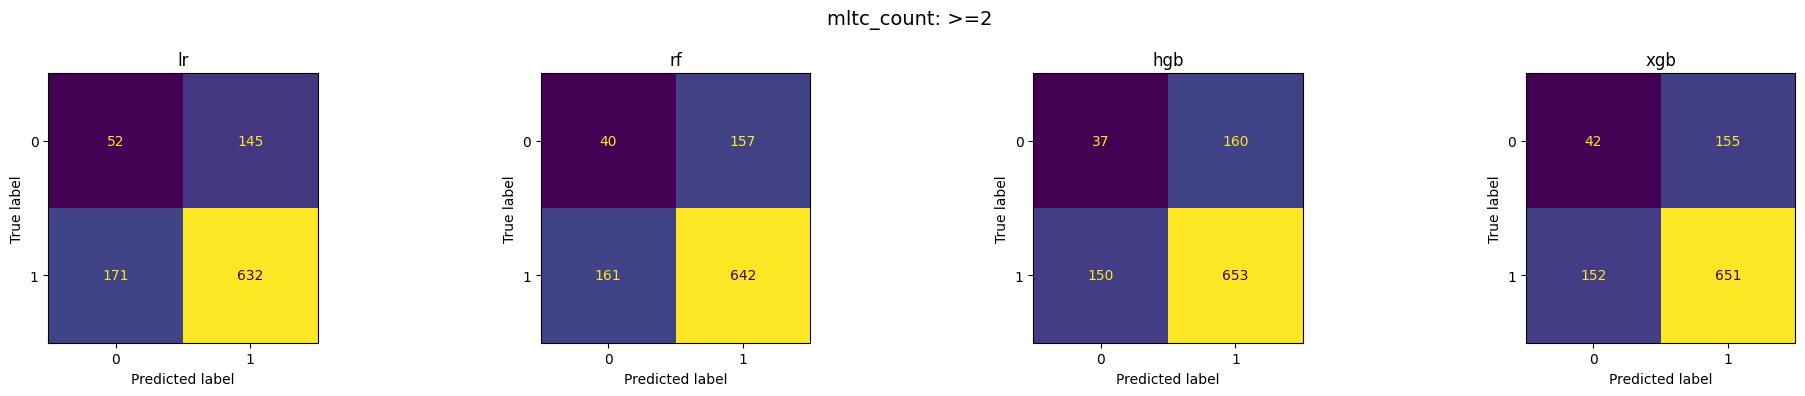

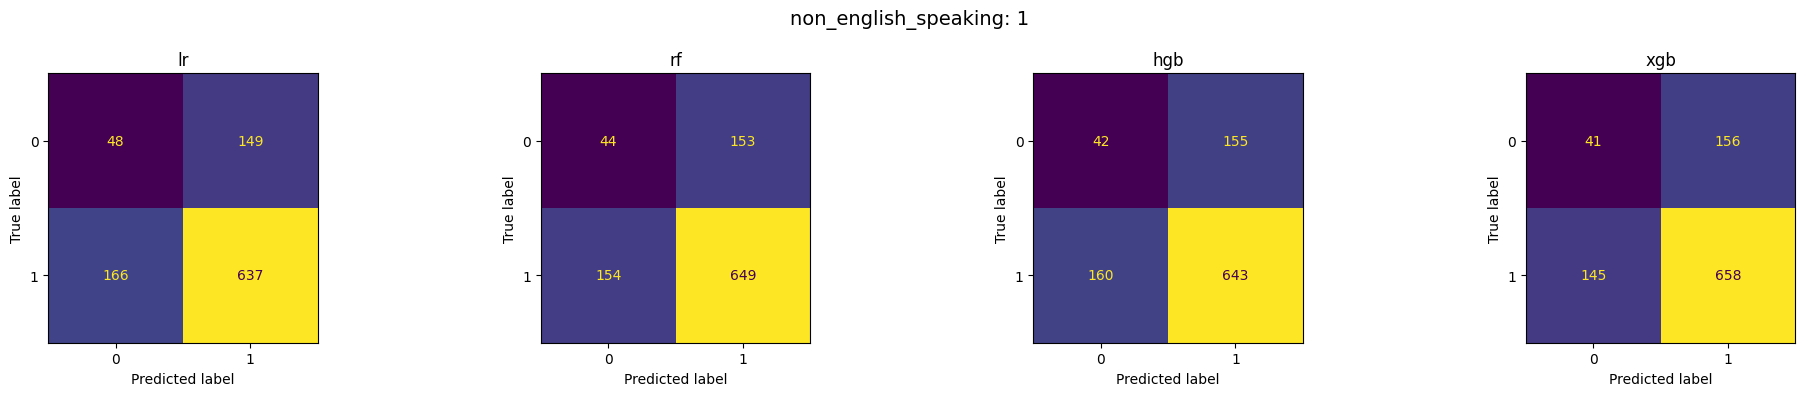

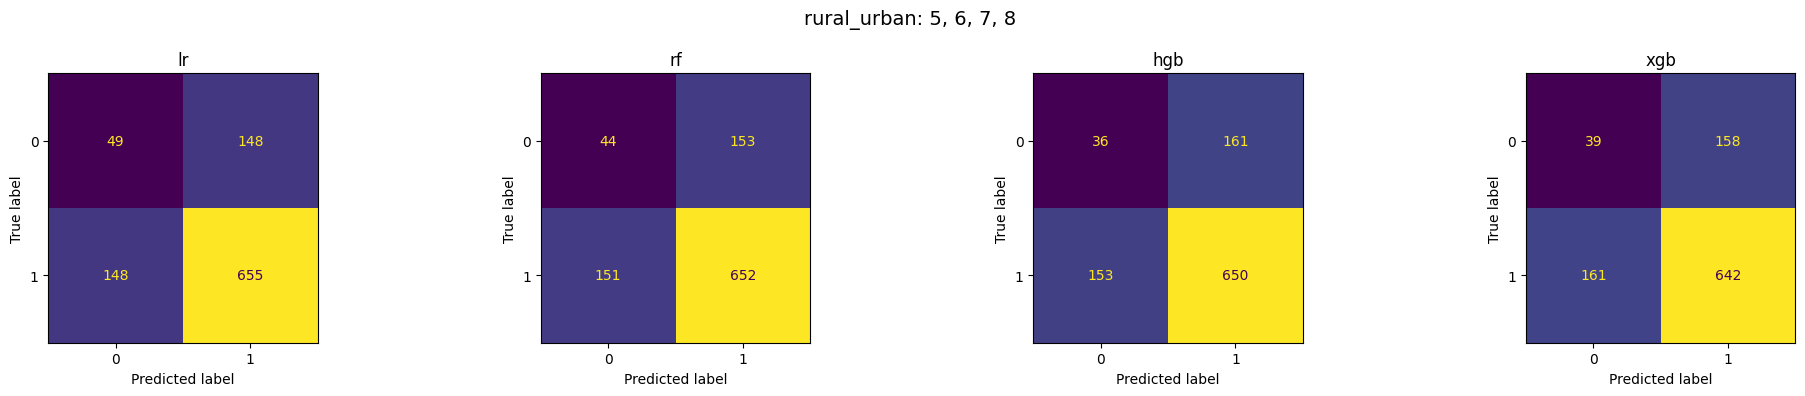

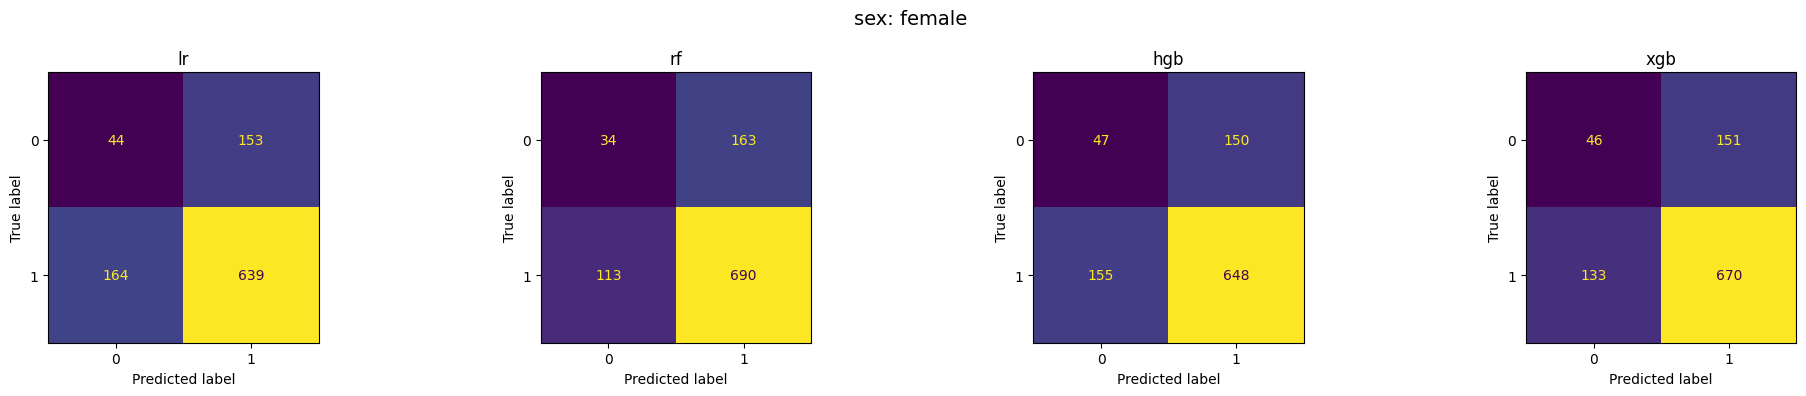

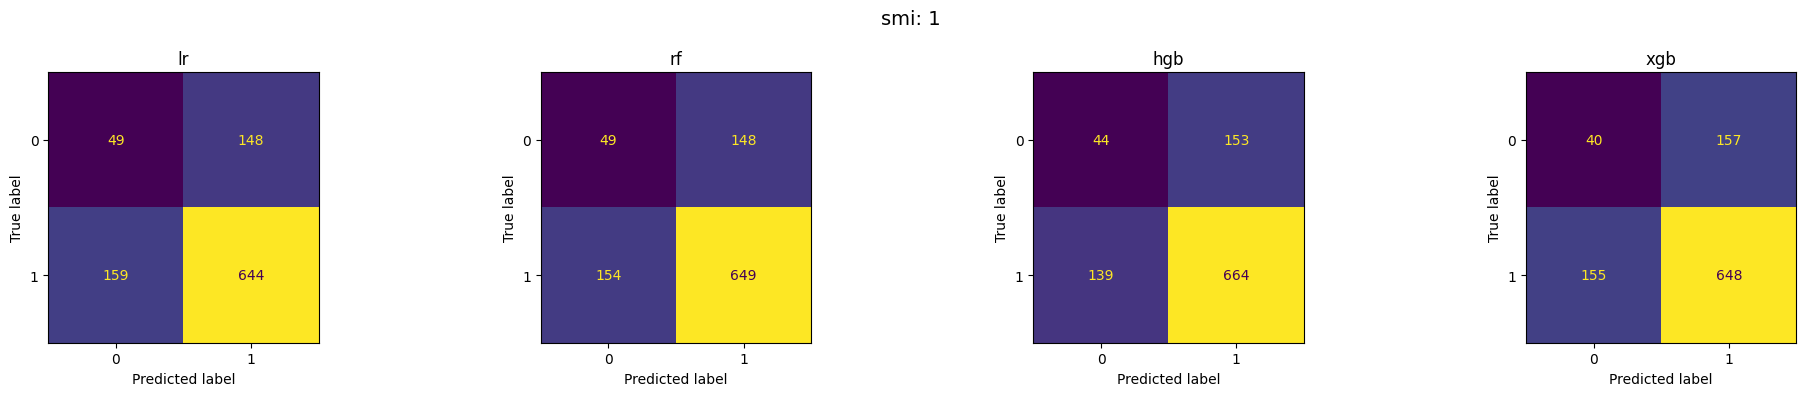

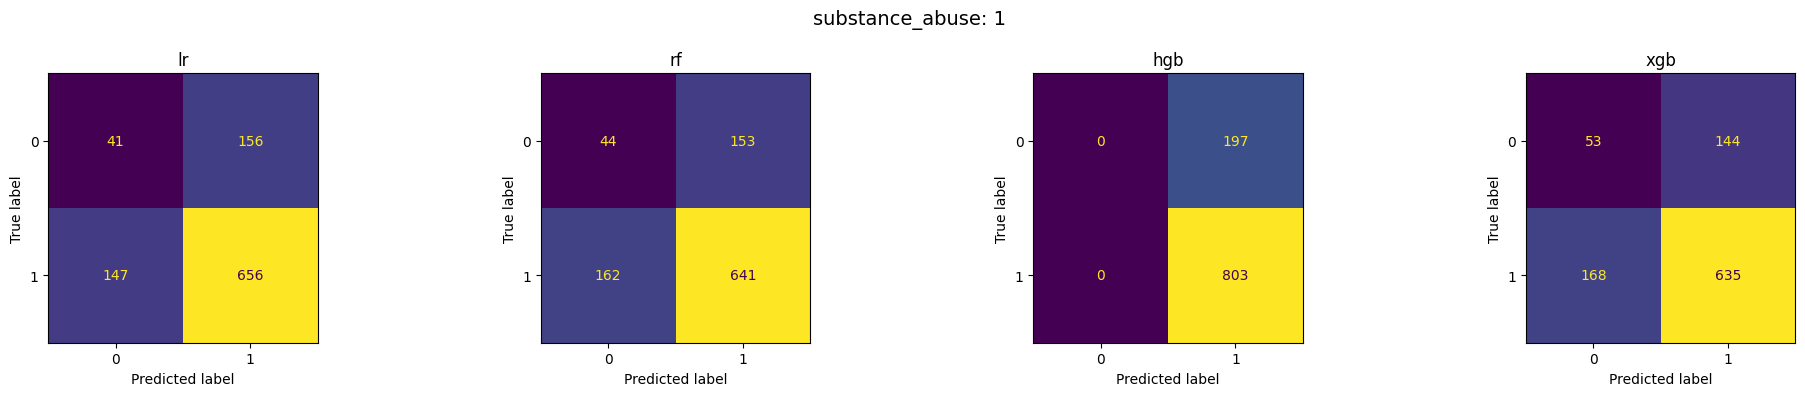

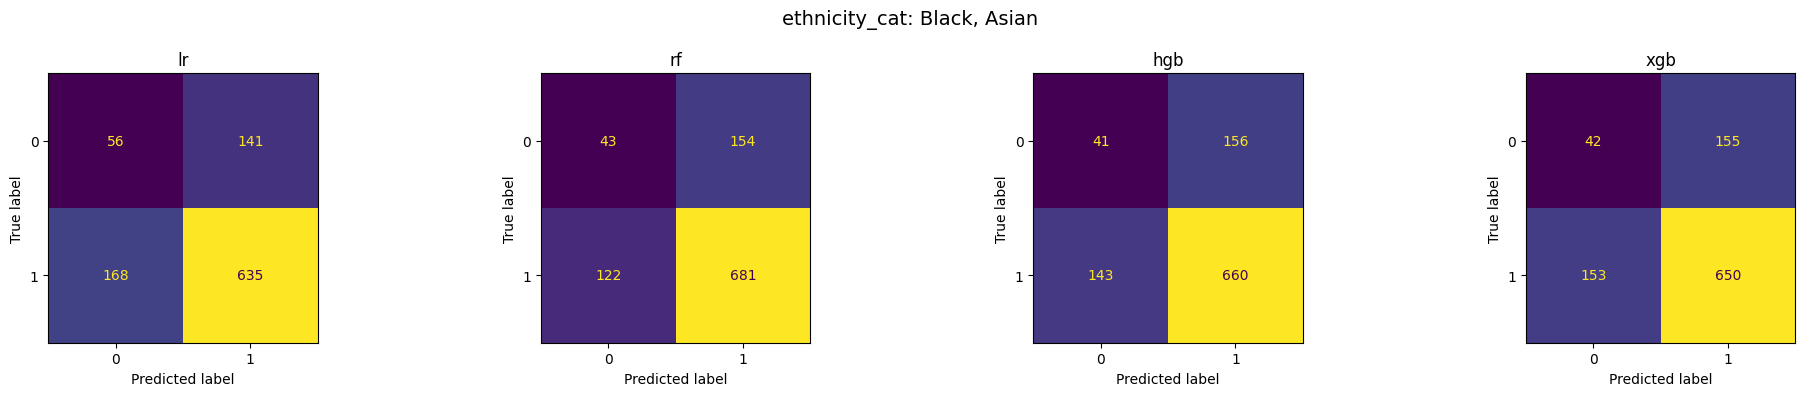

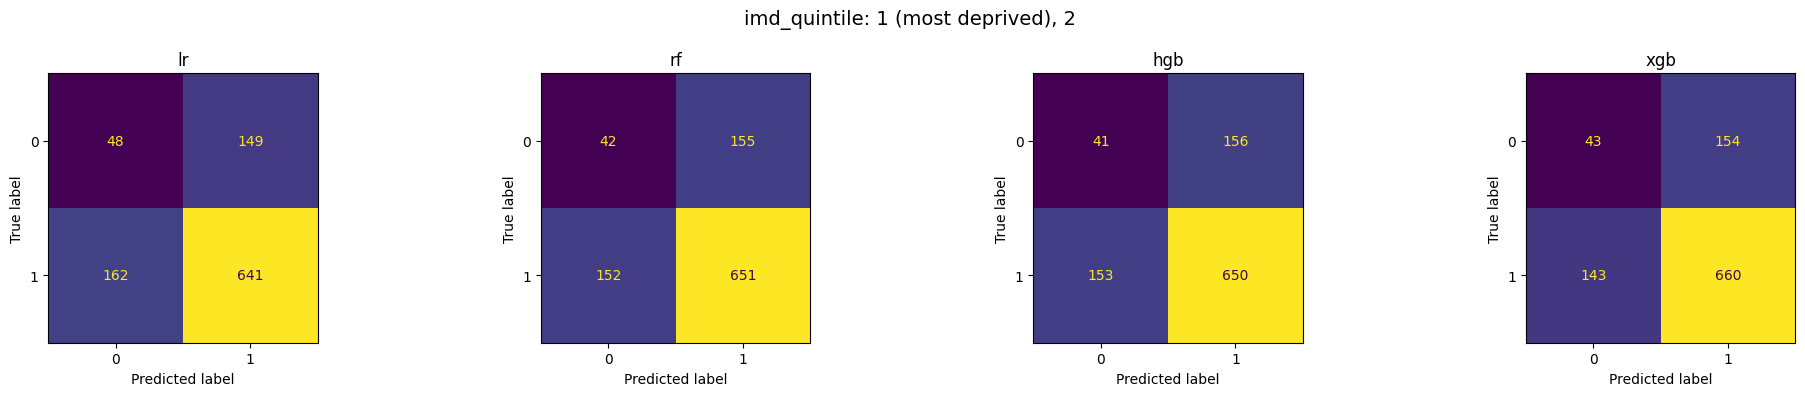

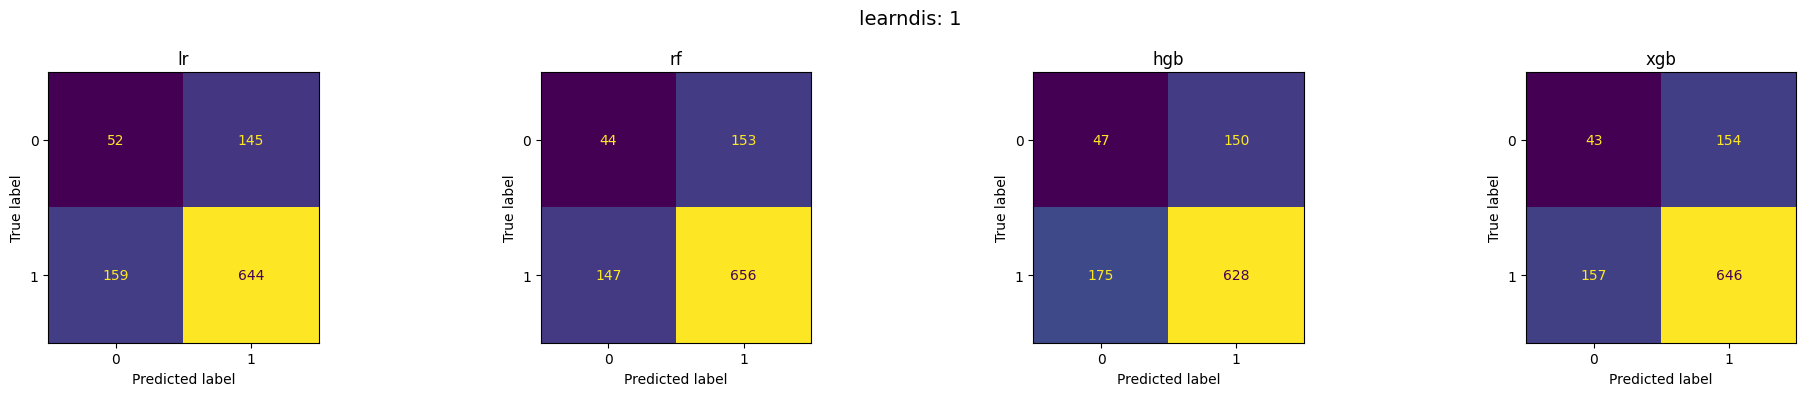

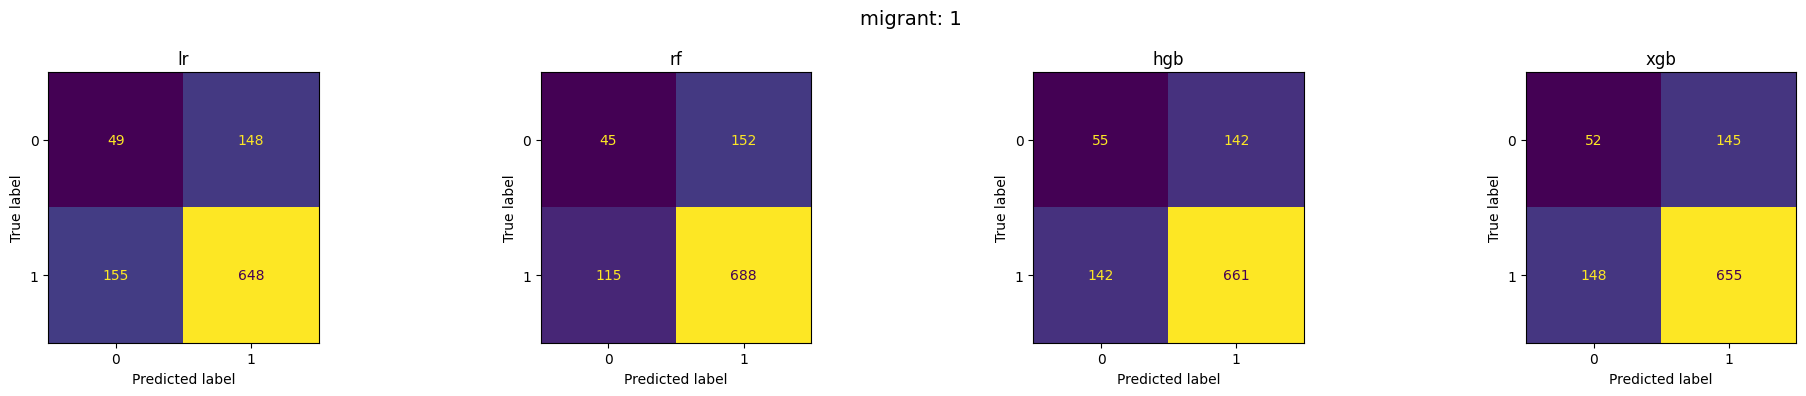

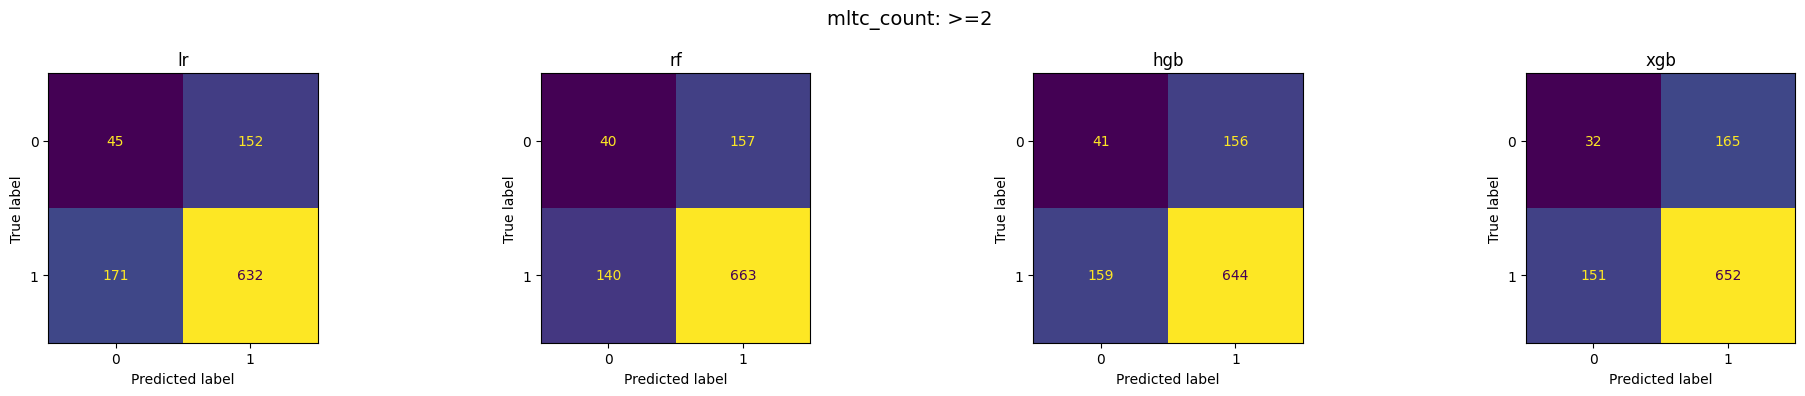

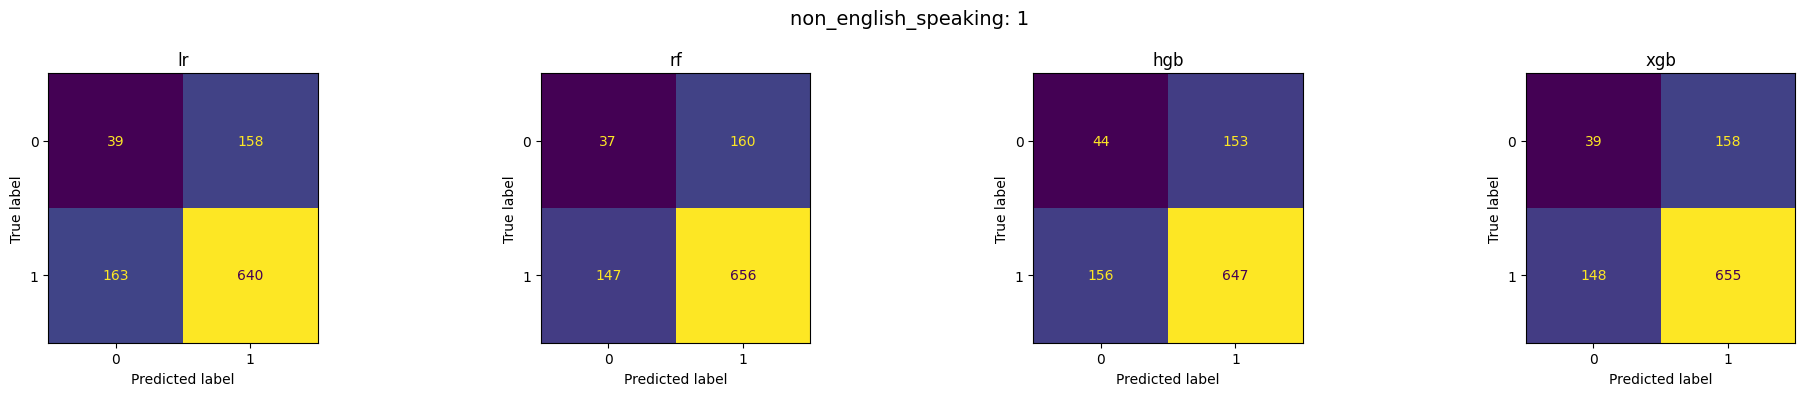

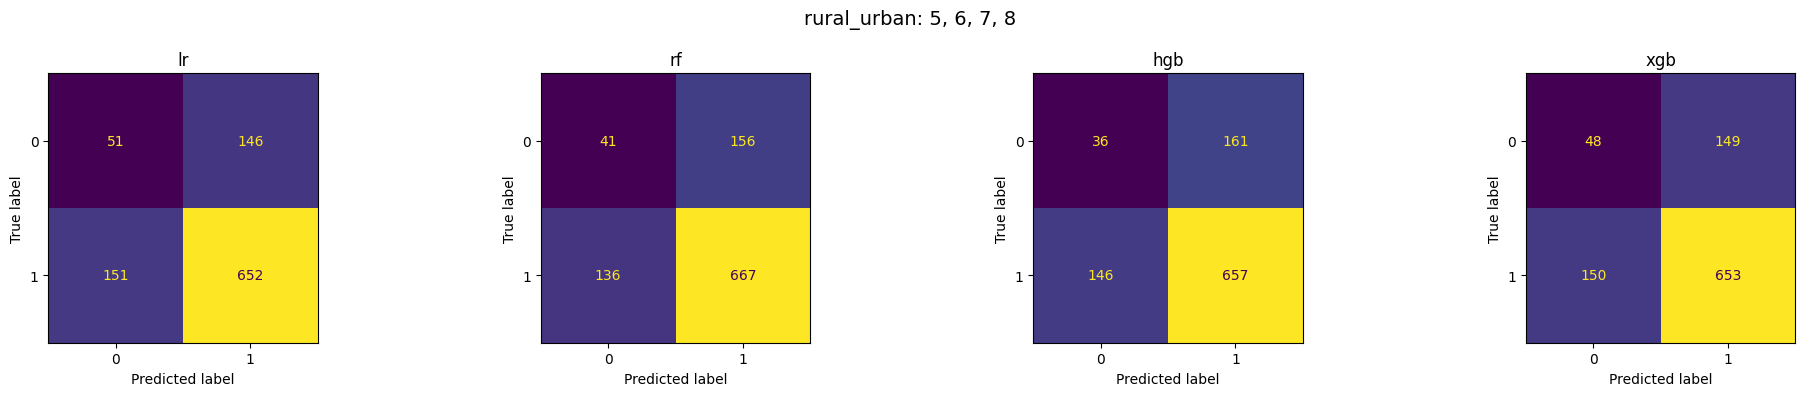

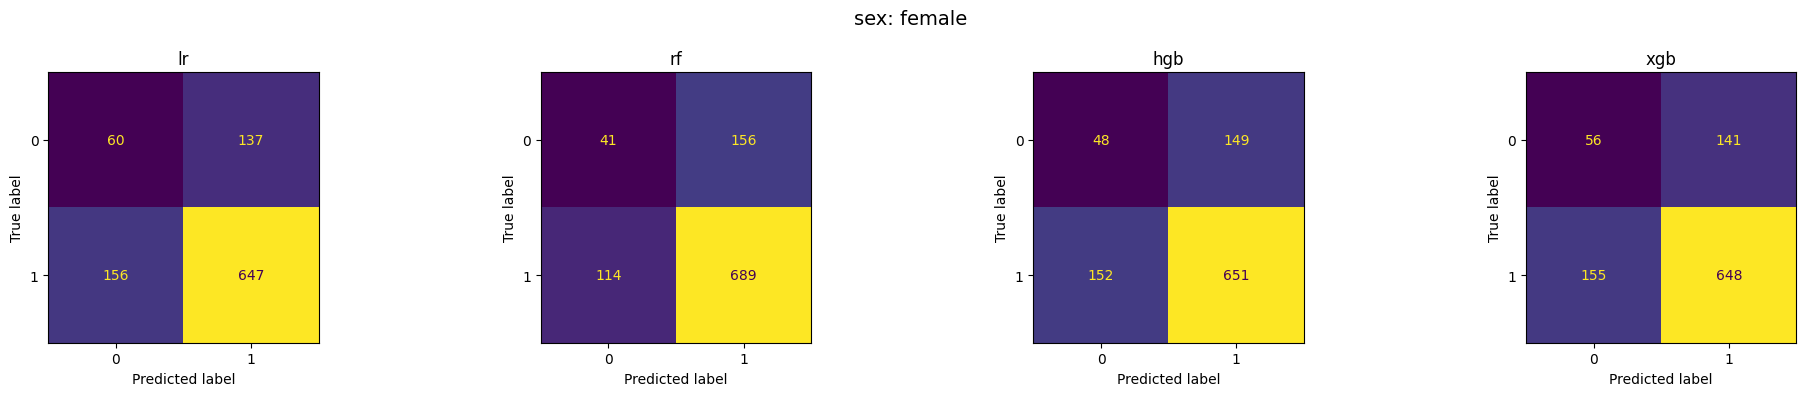

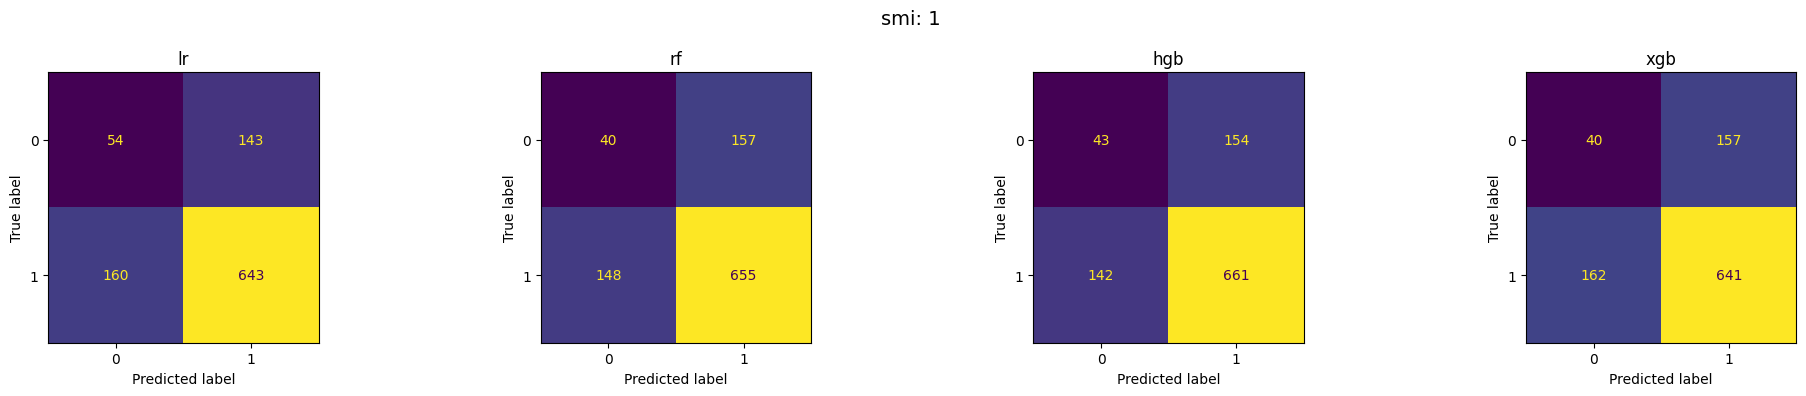

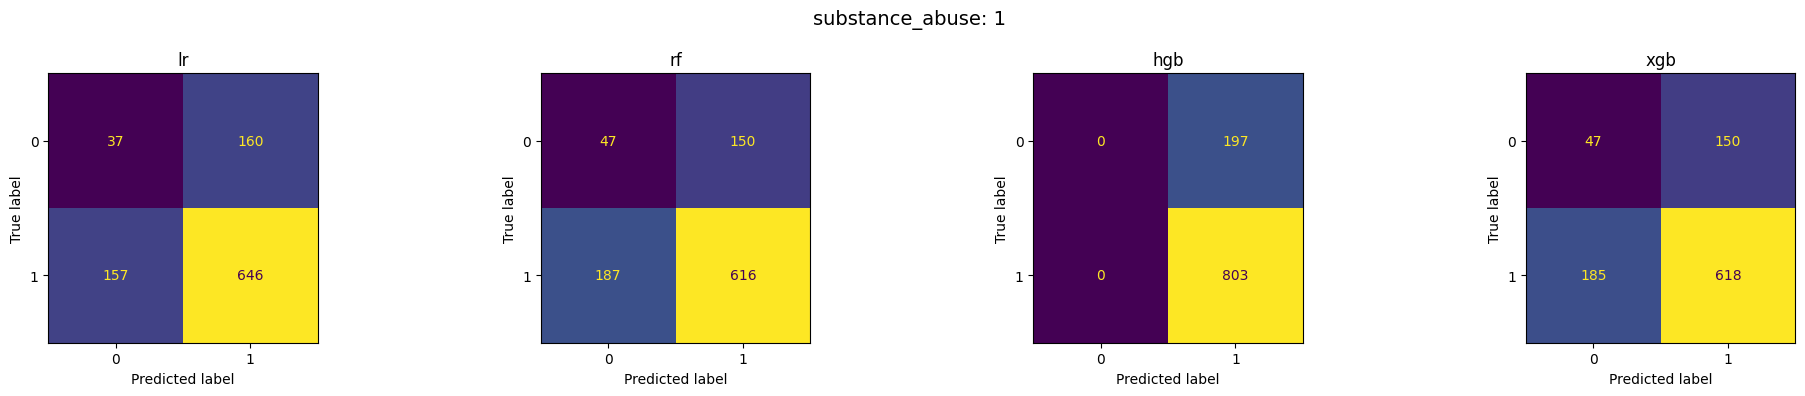

In [8]:
for non_risk_per_risk, ratio_df in performance_df.groupby("non_risk_per_risk"):

    plot_confusion_matrices(
        ratio_df,
        os.path.join(OPTIMISATION_DIR, f"ratio_{non_risk_per_risk}"),
        f"{OPTIMISATION_METHOD}_ratio_{non_risk_per_risk}",
        group_cols=("sampling_variable", "sampling_level"),
    )


## 9. Combined At-Risk Group Settings

In [9]:
COMBINED_METHOD = UNDERSAMPLING_COMBINED_METHOD

COMBINED_DIR = make_output_dir(COMBINED_METHOD)

at_risk_mask = get_at_risk_mask(train_subgroups, COMBINED_AT_RISK_RULES)

at_risk_data = X_train.loc[at_risk_mask]
non_at_risk_data = X_train.loc[~at_risk_mask]

print("Combined at-risk variables:", list(COMBINED_AT_RISK_RULES))
print("At-risk training patients:", len(at_risk_data))
print("Other training patients:", len(non_at_risk_data))

Combined at-risk variables: ['ethnicity_cat', 'imd_quintile', 'mltc_count', 'migrant', 'learndis', 'non_english_speaking', 'smi', 'substance_abuse', 'homeless', 'housebound']
At-risk training patients: 2291
Other training patients: 1709


## 10. Sample, train and evaluate for the combined at-risk group

In [10]:
combined_rows = []
combined_subgroup_rows = []
combined_skipped_rows = []

for non_risk_per_risk in NON_RISK_PER_RISK_VALUES:

    sampling_info = {
        "sampling_variable": "combined_at_risk",
        "sampling_level": "any",
        "non_risk_per_risk": non_risk_per_risk,
    }

    n_non_risk = min(
        len(non_at_risk_data),
        int(len(at_risk_data) * non_risk_per_risk),
    )

    if n_non_risk == len(non_at_risk_data):
        combined_skipped_rows.append({
            **sampling_info,
            "reason": "No patients would be removed",
        })
        continue

    sampled_non_risk = non_at_risk_data.sample(
        n=n_non_risk,
        random_state=RANDOM_STATE,
    )

    selected_rows = at_risk_data.index.append(sampled_non_risk.index)

    X_train_sampled = X_train.loc[selected_rows].copy()
    y_train_sampled = y_train.loc[selected_rows].copy()

    counts = count_classes(
        y_train=y_train_sampled,
        y_test=y_test,
    )

    reason = get_skip_reason(counts)

    if reason is not None:
        combined_skipped_rows.append({
            **sampling_info,
            "reason": reason,
        })
        continue

    print(
        f"Sampling for combined at-risk group: "
        f"ratio = {non_risk_per_risk}"
    )
    print("Training patients before sampling:", len(X_train))
    print("Training patients after sampling:", len(X_train_sampled))
    print("Other patients retained:", len(sampled_non_risk))

    run_dir = os.path.join(
        COMBINED_DIR,
        f"ratio_{non_risk_per_risk}",
    )

    performance, predictions = fit_and_predict(
        X_train=X_train_sampled,
        y_train=y_train_sampled,
        X_test=X_test,
        y_test=y_test,
        test_ids=data["test_ids"],
        out_dir=run_dir,
        cv=cv,
        # threshold from the original (not sampled) training set
        X_threshold=X_train,
        y_threshold=y_train,
    )

    subgroup_performance = evaluate_in_subgroups(
        prediction_df=predictions,
        test_subgroups=test_subgroups,
    )

    for column, value in counts.items():
        performance[column] = value

    for column, value in sampling_info.items():
        performance[column] = value
        subgroup_performance[column] = value

    predictions.to_csv(
        os.path.join(run_dir, "test_predictions.csv.gz"),
        index=False,
        compression="gzip",
    )

    combined_rows.append(performance)
    combined_subgroup_rows.append(subgroup_performance)

Sampling for combined at-risk group: ratio = 0.5
Training patients before sampling: 4000
Training patients after sampling: 3436
Other patients retained: 1145
Fitting 5 folds for each of 6 candidates, totalling 30 fits
lr: best CV roc_auc = 0.5763
lr: best params = {'model__C': 0.1, 'model__l1_ratio': 0.5, 'model__penalty': 'elasticnet', 'model__solver': 'saga'}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
rf: best CV roc_auc = 0.5939
rf: best params = {'n_estimators': 100, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced_subsample'}
Fitting 5 folds for each of 20 candidates, totalling 100 fits
hgb: best CV roc_auc = 0.5816
hgb: best params = {'max_iter': 400, 'max_depth': 2, 'learning_rate': 0.01}
Fitting 5 folds for each of 25 candidates, totalling 125 fits
xgb: best CV roc_auc = 0.5893
xgb: best params = {'subsample': 0.7, 'scale_pos_weight': 0.24854651162790697, 'n_estimators': 30

## 11. Combine and Save

In [ ]:

combined_skipped_df = pd.DataFrame(
    combined_skipped_rows,
    columns=["sampling_variable", "sampling_level", "non_risk_per_risk", "reason"],
)
combined_skipped_df.to_csv(os.path.join(COMBINED_DIR, "skipped_subgroups.csv"), index=False)

combined_df = pd.concat(combined_rows, ignore_index=True)
combined_subgroup_df = pd.concat(combined_subgroup_rows, ignore_index=True)

save_with_sdc(
    combined_df,
    os.path.join(COMBINED_DIR, "test_performance.csv"),
    count_cols=GROUP_COUNT_COLS + CONFUSION_COUNT_COLS,
)

save_with_sdc(
    combined_subgroup_df,
    os.path.join(COMBINED_DIR, "subgroup_test_performance.csv"),
    count_cols=[
        "n_test",
        "test_events",
        "test_nonevents",
        *CONFUSION_COUNT_COLS,
    ],
)

print("Combined sampling  fitted:", len(combined_rows))
print("Combined sampling  skipped:", len(combined_skipped_df))
print("Saved results to:", COMBINED_DIR)

Combined sampling experiments fitted: 1
Combined sampling experiments skipped: 1
Saved results to: /Users/cu20932/Documents/Work/reducehf/output/models/optimisation/undersampling_combined_at_risk
